# Modul 9 — Prediction II: Time Series Forecasting (ARIMA)

**Time series** adalah data yang diurutkan menurut waktu; satu nilai berhubungan dengan nilai sebelumnya, jadi barisnya **tidak independen**.

- **Komponen:** *trend* (arah jangka panjang), *seasonality* (pola berulang periodik), *cyclical*, dan *noise*.
- **ARIMA(p, d, q):** *AR* (p lag nilai sebelumnya), *I* (d kali differencing agar stasioner), *MA* (q lag error sebelumnya).
- **Stasioner:** rata-rata dan varians relatif konstan. Diuji dengan **ADF Test** (p ≤ 0,05 → stasioner); jika belum, lakukan differencing.
- **ACF/PACF** membantu menebak q dan p.
- **Evaluasi:** MAE, RMSE, MAPE.
- Pembagian data **harus kronologis**, bukan acak.

Isi cell kode sendiri di setiap bagian, lalu tulis **Analisis** dan **Konklusi** di cell markdown di bawahnya.

---
## 1. Persiapan Environment & Import Library

### 1.1 Install Library

In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 3.3 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.3 MB 2.1 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/11.3 MB 2.2 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/11.3 MB 2.1 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.3 MB 2.0 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/11.3 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/11.3 MB 1.9 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/11.3 MB 1.8 MB/s eta 0:00:05
   ------------ --------------------------- 3.4/11.3 MB 1.7 MB/s eta 0:00:05
   ------------ --------------------------- 3.7/11.3 MB 1.7 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.3 MB 1.6 MB/s eta 0:00:05
   ----------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Import Library yang Dibutuhkan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error


---
## 2. Pengenalan Dataset Flights

Muat dataset `flights` dengan Seaborn, lalu tampilkan 5 data teratas, `info()`, statistik deskriptif, dan ukuran data.

In [4]:
df = sns.load_dataset('flights')
print(df.head())
df.info()
print(df.describe())
print("Jumlah data:", df.shape)

   year month  passengers
0  1949   Jan         112
1  1949   Feb         118
2  1949   Mar         132
3  1949   Apr         129
4  1949   May         121
<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        144 non-null    int64   
 1   month       144 non-null    category
 2   passengers  144 non-null    int64   
dtypes: category(1), int64(2)
memory usage: 2.9 KB
              year  passengers
count   144.000000  144.000000
mean   1954.500000  280.298611
std       3.464102  119.966317
min    1949.000000  104.000000
25%    1951.750000  180.000000
50%    1954.500000  265.500000
75%    1957.250000  360.500000
max    1960.000000  622.000000
Jumlah data: (144, 3)


---
## 3. Preprocessing Data Time Series

### 3.1 Mengubah Format Tanggal

Ubah `month` menjadi nomor bulan (`pd.to_datetime(..., format='%b')`), gabungkan dengan `year` menjadi kolom `date`, jadikan indeks, lalu ambil kolom `passengers` sebagai `time_series`.

In [5]:
df['month_num'] = pd.to_datetime(
 df['month'],
 format='%b'
).dt.month
df['date'] = pd.to_datetime(
    dict(
 year=df['year'],
 month=df['month_num'],
 day=1
 )
)
df = df.set_index('date')
time_series = df['passengers']
print(time_series.head())

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: passengers, dtype: int64


### 3.2 Pengecekan Missing Values

Hitung jumlah nilai kosong pada `time_series` dan tampilkan `info()`-nya.

In [6]:
print("Missing Value:", time_series.isnull().sum())
print(time_series.info())

Missing Value: 0
<class 'pandas.Series'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Series name: passengers
Non-Null Count  Dtype
--------------  -----
144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None


### 3.3 Resampling Data

Gunakan `time_series.resample('MS').sum()` dan cetak lima nilai pertama serta frekuensinya.

In [7]:
time_series = time_series.resample('MS').sum()
print(time_series.head())
print("Frekuensi:", time_series.index.freq)

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64
Frekuensi: <MonthBegin>


### 3.4 Visualisasi Data Time Series

Buat line chart `time_series` (`marker='o'`) dengan judul, label sumbu, dan grid.

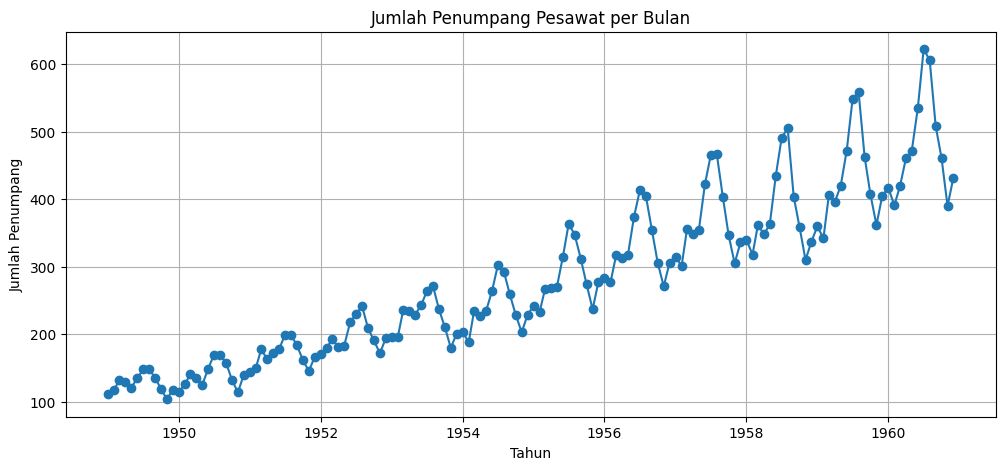

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(time_series, marker='o')
plt.title('Jumlah Penumpang Pesawat per Bulan')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Penumpang')
plt.grid(True)
plt.show()


---
## 4. Pengecekan Stasioneritas Data

### 4.1 Pengujian dengan ADF Test

Jalankan `adfuller(time_series)`, cetak `ADF Statistic` dan `p-value`, lalu tampilkan kesimpulan stasioner atau belum.

In [9]:
adf_result = adfuller(time_series)
print('ADF Statistic:', adf_result[0])
print('p-value:', adf_result[1])
if adf_result[1] <= 0.05:
 print('Data stasioner')
else:
 print('Data belum stasioner')

ADF Statistic: 0.8153688792060482
p-value: 0.991880243437641
Data belum stasioner


C:\Users\advan\AppData\Local\Temp\ipykernel_6428\1519765636.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(time_series)


### 4.2 Melakukan Differencing

Hitung `time_series.diff().dropna()`, tampilkan 5 nilai pertama, jalankan ADF Test lagi, dan cetak kesimpulannya.

In [11]:
time_series_diff = time_series.diff().dropna()
print(time_series_diff.head())
adf_result_diff = adfuller(time_series_diff)
print('ADF Statistic:', adf_result_diff[0])
print('p-value:', adf_result_diff[1])
if adf_result_diff[1] <= 0.05:
 print('Data setelah differencing stasioner')
else:
 print('Data masih belum stasioner')

date
1949-02-01     6.0
1949-03-01    14.0
1949-04-01    -3.0
1949-05-01    -8.0
1949-06-01    14.0
Freq: MS, Name: passengers, dtype: float64
ADF Statistic: -2.8292668241699994
p-value: 0.0542132902838255
Data masih belum stasioner


C:\Users\advan\AppData\Local\Temp\ipykernel_6428\2587524368.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result_diff = adfuller(time_series_diff)


### 4.3 Visualisasi Hasil Differencing

Buat line chart `time_series_diff` dengan judul "Data Setelah Differencing Pertama" dan label sumbu yang jelas.

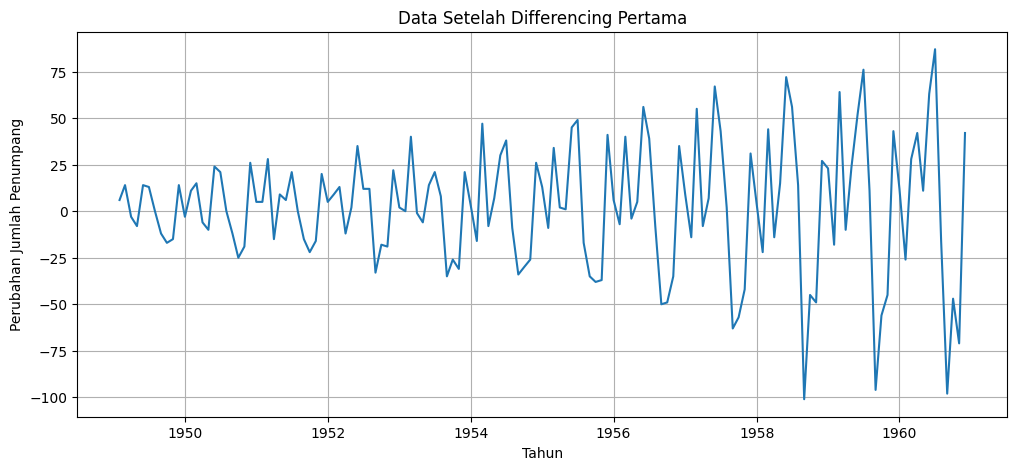

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(time_series_diff.index, time_series_diff.values)
plt.title("Data Setelah Differencing Pertama")
plt.xlabel("Tahun")
plt.ylabel("Perubahan Jumlah Penumpang")
plt.grid(True)
plt.show()

---
## 5. Menentukan Parameter ARIMA (p, d, q)

### 5.1 Visualisasi ACF

Buat grafik ACF dari `time_series_diff` dengan `plot_acf(..., lags=30)`.

### 5.2 Visualisasi PACF

Buat grafik PACF dari `time_series_diff` dengan `plot_pacf(..., lags=30, method='ywm')`.

### 5.3 Menentukan Parameter Model

Tetapkan parameter model awal ARIMA(2, 1, 2) ke variabel `p`, `d`, `q` dan cetak.

---
## 6. Pembagian Data Training dan Testing

Bagi `time_series` secara kronologis: 90% awal sebagai `train`, 10% akhir sebagai `test`. Cetak jumlah dan periode masing-masing.

---
## 7. Implementasi Model ARIMA

Buat model `ARIMA(train, order=(2, 1, 2))`, latih dengan `.fit()`, dan cetak `.summary()`.

---
## 8. Melakukan Prediksi (Forecasting)

Ramal sepanjang data testing dengan `model_fit.forecast(steps=len(test))`, beri indeks `test.index`, lalu plot data training, data aktual, dan hasil prediksi dalam satu gambar.

---
## 9. Evaluasi Model ARIMA

Hitung MAE (`mean_absolute_error`), RMSE (akar `mean_squared_error`), dan MAPE (rata-rata selisih relatif × 100) antara `test` dan `forecast`.

---
## 10. Forecasting 12 Bulan ke Depan

Latih ulang `ARIMA(time_series, order=(2, 1, 2))` dengan seluruh data, ramal 12 bulan (`future_forecast`), lalu plot data historis dan ramalannya.

---
## 11. Catatan Penting Praktikum

- Time series: data berurutan, bagi data secara kronologis (bukan acak).
- Data harus stasioner; uji dengan ADF; trend dihilangkan dengan differencing.
- ARIMA(p, d, q): AR (lag nilai), I (differencing), MA (lag error); ACF/PACF hanya petunjuk.
- Evaluasi: MAE, RMSE, MAPE; bandingkan dengan ramalan sederhana.
- Forecast adalah estimasi berdasarkan pola historis, bukan angka pasti.

---
## 12. Latihan Mandiri

**Tugas mahasiswa:**

**Studi Kasus: Prediksi Suhu Rata-rata Harian**

Dataset: **Daily Climate Time Series Data** (Kaggle: `sumanthvrao/daily-climate-time-series-data`). Gunakan file **`DailyDelhiClimateTrain.csv`**. *Catatan: unduhan dari Kaggle membutuhkan akun Kaggle; bila kesulitan, minta file CSV kepada aslab.*

1. Unduh dataset dari Kaggle dan gunakan file `DailyDelhiClimateTrain.csv`.
2. Ubah kolom `date` menjadi format datetime dan jadikan sebagai indeks.
3. Gunakan variabel `meantemp` sebagai target peramalan.
4. Visualisasikan pola perubahan suhu rata-rata harian menggunakan line chart.
5. Lakukan pengujian stasioneritas menggunakan ADF Test.
6. Jika data belum stasioner, lakukan differencing hingga memenuhi kondisi stasioneritas.
7. Tampilkan grafik ACF dan PACF untuk membantu menentukan kandidat parameter ARIMA.
8. Bangun minimal dua model ARIMA dengan kombinasi parameter (p, d, q) yang berbeda.
9. Bagi data secara kronologis menjadi data training dan testing dengan proporsi 80:20.
10. Evaluasi hasil peramalan menggunakan MAE, RMSE, dan MAPE.
11. Bandingkan performa kedua model dan tentukan model dengan hasil evaluasi terbaik.
12. Buat peramalan suhu rata-rata untuk 30 hari berikutnya menggunakan model terbaik.

**Catatan:** Setiap langkah ditulis **Analisis** dan **Konklusi**-nya di cell markdown di bawah kode. Jawaban untuk perbandingan model (nomor 11) ditulis dalam teks markdown.